## Amazon customer reviews: Exploratory (Big) Data Analysis

Adrian Galido | Shehab Ibrahim

BDCC MSDS 2019

### EXECUTIVE SUMMARY

The exploratory data analysis, or EDA, can provide a variety of insights when applied to customer reviews. Using select data from the Amazon customer review data to employ the EDA. Ten product categories organized within the "home retail" theme, as agreed by the proponents, were utilized. The project makes an attempt to view the temporal aspect of customer preferences from two perspectives - the product retailer viewpoint and the product designer viewpoint. The EDA draw on generating visualizations with the utility of charts (line, heatmaps, and bar charts). The results indicate a dip in the number of customer reviewers at certain months of the year. This seasonality was evident not only in the engagement of customer reviewers but also in their (aggregate) preferences as well. Product retailers and designers can leverage on this in their marketing efforts. Future work can proceed to explore seasonality on a micro-level, i.e., per item level.

### INTRODUCTION

_Data source_

The Amazon customer reviews dataset, the data source for this project, is a collection of customer reviews for the the different product categories and products available on Amazon.com. An extensive description of the dataset can be found in https://s3.amazonaws.com/amazon-reviews-pds/readme.html. For our purpose, the data have been obtained from '/mnt/localdata/public/amazon-reviews/'.

_Problem statement and motivation_

We attempt to conduct an exploratory data analysis of Amazon customer reviews. From the several product categories available, we limit our selection to 10. In selecting the product categories, we considered "home-related" as the central theme. Why does this project matter? Several studies exploring the customer reviews, specifically the dataset from Amazon, has focus on areas as opinion mining [1], product ranking [2], feature extraction [3], and sentiment analysis [4]. This project serves to explore the temporal aspect of customer preferences. From a methodological perspective, to our knowledge, only a limited number of studies has exploited the domain area of customer preferences over time.

Specifically, we put forward several questions from two perspectives - product retailer perspective and product designer perspective.

Product retailer
1. How many reviewers do we have for each product category?
1. Are the numbers of reviewers increasing per year? 
1. What are the seasonal (monthly) patterns in the number of reviewers?

Product designer
1. What has been the ratings per product category?
1. What are the average ratings of the product categories?
1. What are the average ratings of the product categories over time (yearly)?
1. What are the seasonal (monthly) average ratings of the product categories?
1. Which products have the top rating? bottom rating?
1. How many unique reviewers are there?
1. Which reviewers had the highest number of (helpful) reviews per category?
1. From selected categories, which products have the highest number of reviews?

### DATA COLLECTION AND DESCRIPTION

_Data format and metadata_

Each of the (data) files contain the following attributes:

<table>
  <tr><th style="text-align:left">Attribute</th><th style="text-align:left">Description</th></tr>
  <tr><td style="text-align:left">marketplace</td><td style="text-align:left">2 letter country code of the marketplace where the review was written.</td></tr>
  <tr><td style="text-align:left">customer_id</td><td style="text-align:left">Random identifier that can be used to aggregate reviews written by a single author.</td></tr>
  <tr><td style="text-align:left">review_id</td><td style="text-align:left">The unique ID of the review.</td></tr>
  <tr><td style="text-align:left">product_id</td><td style="text-align:left">The unique Product ID the review pertains to. In the multilingual dataset the reviews <br>for the same product in different countries can be grouped by the same product_id.</td></tr>
  <tr><td style="text-align:left">product_parent</td><td style="text-align:left">Random identifier that can be used to aggregate reviews for the same product.</td></tr>
  <tr><td style="text-align:left">product_title</td><td style="text-align:left">Title of the product.</td></tr> 
  <tr><td style="text-align:left">product_category </td><td style="text-align:left">Broad product category that can be used to group reviews (also used to group <br>the dataset into coherent parts).</td></tr>
  <tr><td style="text-align:left">star_rating</td><td style="text-align:left">The 1-5 star rating of the review.</td></tr>
  <tr><td style="text-align:left">helpful_votes</td><td style="text-align:left">Number of helpful votes.</td></tr>    
  <tr><td style="text-align:left">total_votes</td><td style="text-align:left">Number of total votes the review received.</td></tr>  
  <tr><td style="text-align:left">vine</td><td style="text-align:left">Review was written as part of the Vine program.</td></tr>
  <tr><td style="text-align:left">verified_purchase</td><td style="text-align:left">The review is on a verified purchase.</td></tr>
  <tr><td style="text-align:left">review_headline</td><td style="text-align:left">The title of the review.</td></tr>
  <tr><td style="text-align:left">review_body</td><td style="text-align:left">The review text.</td></tr>
  <tr><td style="text-align:left">review_date</td><td style="text-align:left">The date the review was written.</td></tr>
</table>

### EXPLORATORY DATA ANALYSIS / MODEL AND RESULTS

The exploratory data analysis conducted draw on generating visualizations with the utility of charts (line, heatmaps, and bar charts). The libraries dask, pandas, and matplotlib were the primaries.

### A. Preliminaries

**A-1 Load libraries / modules needed**

In [1]:
import numpy as np
import pandas as pd

import re
import glob
import zipfile
from operator import itemgetter
from collections import Counter

import dask.bag as db
import dask.array as da
import dask.dataframe as dd
from dask.delayed import delayed
from dask.diagnostics import ProgressBar
from dask_ml.cluster import KMeans
from dask.distributed import Client
#client = Client('10.233.24.232:8786')
pbar = ProgressBar()
pbar.register()

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set()

import warnings
warnings.filterwarnings('ignore')

**A-2 Path, filenames and selection.**

We selected a collection of 10 files associated with the theme "home retail" - home improvement, lawn and garden, kitchen, home entertainment, home, health & personal care, grocery, furniture, apparel and baby.

In [3]:
path = '/mnt/localdata/public/amazon-reviews/'

In [4]:
filenames = ['amazon_reviews_us_Home_Improvement_v1_00.tsv.gz',
             'amazon_reviews_us_Lawn_and_Garden_v1_00.tsv.gz',
            'amazon_reviews_us_Kitchen_v1_00.tsv.gz',
            'amazon_reviews_us_Home_Entertainment_v1_00.tsv.gz',
            'amazon_reviews_us_Home_v1_00.tsv.gz',
            'amazon_reviews_us_Health_Personal_Care_v1_00.tsv.gz',
            'amazon_reviews_us_Grocery_v1_00.tsv.gz',
            'amazon_reviews_us_Furniture_v1_00.tsv.gz',
            'amazon_reviews_us_Apparel_v1_00.tsv.gz',
            'amazon_reviews_us_Baby_v1_00.tsv.gz']

In [5]:
selected_filenames = ['amazon_reviews_us_Home_v1_00.tsv.gz',
            'amazon_reviews_us_Health_Personal_Care_v1_00.tsv.gz',
            'amazon_reviews_us_Apparel_v1_00.tsv.gz']

In [6]:
import re
product_categories = []
for fn in filenames:
 #   fn = 'amazon_reviews_us_Lawn_and_Garden_v1_00.tsv.gz'
    line = re.search(r"""(?<=amazon_reviews_us_)(.*)(?=_v1_00.tsv.gz)""", fn)
    line =  line[1].replace("_"," ")
    product_categories.append(line)
product_categories.append('Health & Personal Care')

### B. Product retailers perspective

The Amazon customer reviews dataset is a rich source of viewpoints for retailers. We take into consideration 3 potential questions of interest:

+ How many reviewers do we have for each product category? This question revolves around how many customers have interest in the product category. We posit that customer reviewers can be a proxy for sales. The more sales, the better it will be for the firm.

+ Are the numbers of reviewers increasing per year? As we are concerned with temporal patterns, we are interested to know the aggregate uptake of the product category.

+ What are the seasonal (monthly) patterns in the number of reviewers? Seasonality of product reviews has to be considered as well as "buzz" around products can improve the company's bottom line.

In [7]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['customer_id','product_category','review_date'], dtype = {'star_rating':'object'}
                           )
       for fn in filenames]
df = dd.from_delayed(dfs).persist()

[########################################] | 100% Completed | 16.5s
[########################################] | 100% Completed |  1min 41.1s


In [8]:
df.info

<bound method DataFrame.info of Dask DataFrame Structure:
               customer_id product_category review_date
npartitions=10                                         
                     int64           object      object
                       ...              ...         ...
...                    ...              ...         ...
                       ...              ...         ...
                       ...              ...         ...
Dask Name: from-delayed, 10 tasks>

In [9]:
df.head()

[########################################] | 100% Completed |  0.1s


,customer_id,product_category,review_date
0,48881148,Home Improvement,2015-08-31
1,47882936,Home Improvement,2015-08-31
2,44435471,Home Improvement,2015-08-31
3,28377689,Home Improvement,2015-08-31
4,50134766,Home Improvement,2015-08-31


In [10]:
df.tail()

[########################################] | 100% Completed |  0.1s


,customer_id,product_category,review_date
1749185,52873209,Baby,1999-07-14
1749186,51161415,Baby,1999-07-14
1749187,52165416,Baby,1999-07-13
1749188,52784607,Baby,1999-07-13
1749189,52165046,Baby,1999-07-13


**B-1 How many reviewers do we have for each product category?**

_"Who likes what (product category)?"_ As mentioned earlier, picking a collection of reviews associated with "home retail", customer reviewers are have taken interest the most with home products, apparel, health & personal care, kitchen, and home improvement.

In [11]:
df_rvws = df[df.product_category.isin(product_categories)]c

In [12]:
df_rvws.head()

[########################################] | 100% Completed |  0.3s


,customer_id,product_category,review_date
0,48881148,Home Improvement,2015-08-31
1,47882936,Home Improvement,2015-08-31
2,44435471,Home Improvement,2015-08-31
3,28377689,Home Improvement,2015-08-31
4,50134766,Home Improvement,2015-08-31


In [13]:
df_rvws = df_rvws.drop('review_date', axis = 1)

In [14]:
df_cust = df_rvws.groupby('product_category')['customer_id'].apply(lambda x: len(x.unique())).compute()

[########################################] | 100% Completed | 43.4s


In [15]:
df_cust

product_category
Health & Personal Care    3088917
Apparel                   3219107
Furniture                  655738
Home Improvement          1707871
Kitchen                   2828324
Home Entertainment         609771
Baby                       960674
Lawn and Garden           1630993
Grocery                   1360244
Home                      3466281
Name: customer_id, dtype: int64

Text(0,0.5,'Product categories')

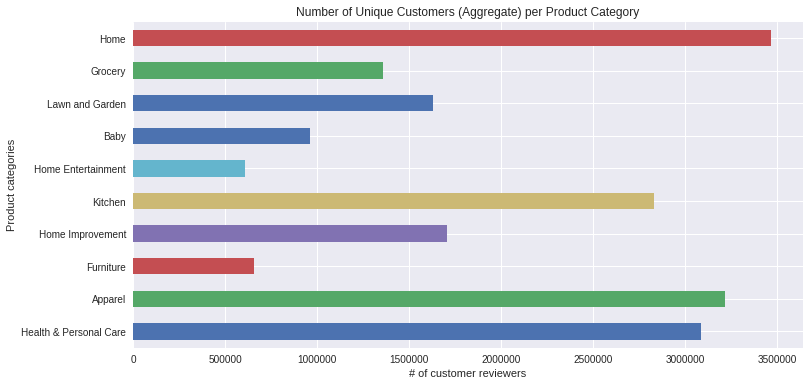

In [16]:
plt.figure(figsize=(12,6))
df_cust.plot(kind='barh')
plt.title('Number of Unique Customers (Aggregate) per Product Category')
plt.xlabel("# of customer reviewers")
plt.ylabel("Product categories")

**B-2 Are the numbers of reviewers increasing per year?**

_"Who takes interest in what over time? Is the customer base growing?"_

In [17]:
dfY = df[df.product_category.isin(product_categories)]

In [18]:
dfY['year'] = dfY['review_date'].str.slice(0,4)

In [19]:
dfY.head()

[########################################] | 100% Completed |  1.6s


,customer_id,product_category,review_date,year
0,48881148,Home Improvement,2015-08-31,2015
1,47882936,Home Improvement,2015-08-31,2015
2,44435471,Home Improvement,2015-08-31,2015
3,28377689,Home Improvement,2015-08-31,2015
4,50134766,Home Improvement,2015-08-31,2015


In [20]:
del dfY['review_date']

In [21]:
dfY['year'] = dfY['year'].astype(str)

In [22]:
dfY['year'].unique().compute()

[########################################] | 100% Completed | 40.2s


0     2015
1        5
2        4
3        3
4        1
5        2
6      nan
7     2014
8     2013
9     2012
10    2011
11    2010
12    2009
13    2008
14    2007
15    2006
16    2005
17    2004
18    2003
19    2002
20    2001
21    2000
22    1999
23    1998
Name: year, dtype: object

In [23]:
list_years = np.arange(1999,2016,1)
list_years=list_years.astype(str)
dfY = dfY[dfY.year.isin(list_years)]

In [24]:
dfY['year'] =dfY['year'].astype(int)

In [25]:
dfY['year'].unique().compute()

[########################################] | 100% Completed | 53.8s


0     2015
1     2014
2     2013
3     2012
4     2011
5     2010
6     2009
7     2008
8     2007
9     2006
10    2005
11    2004
12    2003
13    2002
14    2001
15    2000
16    1999
Name: year, dtype: int64

In [26]:
prod_categ = dfY.product_category.unique().compute()

[########################################] | 100% Completed | 54.3s


In [27]:
countCust = []
for prod in prod_categ.values:
    newDF =  dfY[dfY.product_category == prod]
    dfYCount = newDF.groupby('year')['customer_id'].apply(lambda x: len(x.unique())).compute()
    dfYCountSorted = dfYCount.sort_index()
    countCust.append([dfYCountSorted.index,dfYCountSorted.values])

[########################################] | 100% Completed |  1min  3.8s
[########################################] | 100% Completed |  1min  3.9s
[########################################] | 100% Completed |  1min  6.3s
[########################################] | 100% Completed |  1min  0.2s
[########################################] | 100% Completed |  1min  6.7s
[########################################] | 100% Completed |  1min  6.4s
[########################################] | 100% Completed |  1min  2.6s
[########################################] | 100% Completed | 59.7s
[########################################] | 100% Completed |  1min  7.3s
[########################################] | 100% Completed |  1min  1.0s


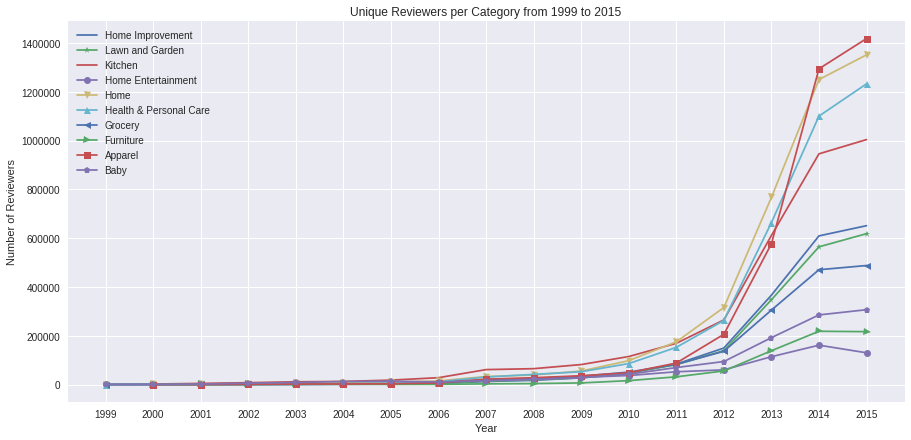

In [28]:
# import seaborn as sns;sns.set()
markers = ['x','*','+','o','v','^','<','>','s','p']
#i = 0
ticks = dfYCountSorted.index
vals = dfYCountSorted.values
#plt.
plt.figure(figsize=(15,7))
for i,u in zip(prod_categ.values,range(0,len(prod_categ.values))):
    plt.plot(countCust[u][0], countCust[u][1], marker = markers[u], label = i )
    plt.xticks(ticks)
    plt.legend()
    plt.title("Unique Reviewers per Category from 1999 to 2015")
    plt.xlabel("Year")
    plt.ylabel("Number of Reviewers")

For the product categories selected, between 1999 to 2015, customer reviewers remained flat up until 2006. Perhaps the uptake of the product review portals have some getting used to. From 2006 onwards, there a growth in the number of reviewers.

**B-3 What are the seasonal (monthly) patterns in the number of reviewers?**

_"Who takes interest in what, when? Is the customer base stable across the months?_" The succeeding charts, on this section, below show that the number of customer reviewers dip between various month-of-the-year, particularly during January to February, March to April, and August to September.

In [29]:
df.head()

[########################################] | 100% Completed |  0.1s


,customer_id,product_category,review_date
0,48881148,Home Improvement,2015-08-31
1,47882936,Home Improvement,2015-08-31
2,44435471,Home Improvement,2015-08-31
3,28377689,Home Improvement,2015-08-31
4,50134766,Home Improvement,2015-08-31


In [30]:
dfM = df[df.product_category.isin(product_categories)]

In [31]:
dfM ['month'] = dfM ['review_date'].str.slice(5,7)

In [32]:
del dfM['review_date']

In [33]:
dfM.head()

[########################################] | 100% Completed |  2.1s


,customer_id,product_category,month
0,48881148,Home Improvement,08
1,47882936,Home Improvement,08
2,44435471,Home Improvement,08
3,28377689,Home Improvement,08
4,50134766,Home Improvement,08


In [34]:
list_months = ['01','02','03','04','05','06','07','08','09','10','11','12']
dfM = dfM[dfM.month.isin(list_months)]

In [35]:
dfMM = dfM.groupby('month')['customer_id'].apply(lambda x:len(x)).compute()

[########################################] | 100% Completed |  1min 52.4s


In [36]:
dfMM.index = dfMM.index.astype(int)
dfMM = dfMM.sort_index()

Text(0,0.5,'Number of Customers')

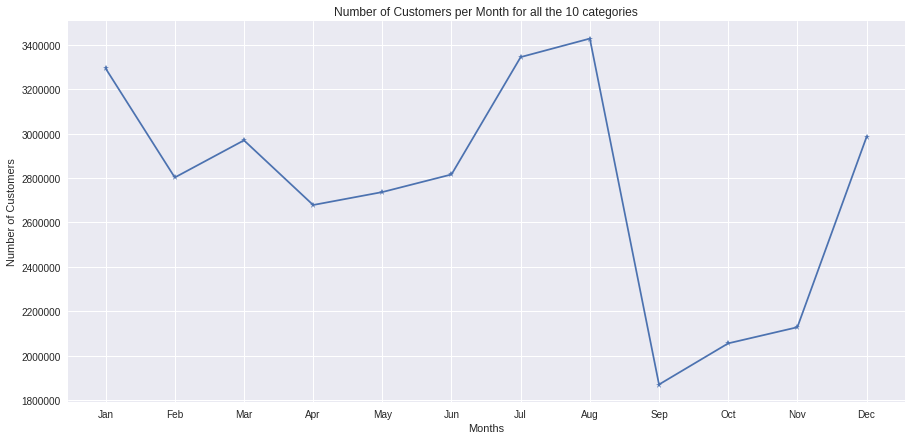

In [37]:
import seaborn as sns;sns.set()

months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plt.figure(figsize=(15,7))
plt.plot(dfMM.index, dfMM.values, marker = '*')
plt.xticks(dfMM.index, months)
plt.title("Number of Customers per Month for all the 10 categories")
plt.xlabel("Months")
plt.ylabel("Number of Customers")


The activity level of customer reviewers appear to be seasonal. Looking at the chart, immediately above, the number of reviewers take a dip on various points. What appears interesting, apart from the drastic decline between August to September, is that there are more up (increase) than down (decrease) in the year.

In [38]:
dfM.head()

[########################################] | 100% Completed |  2.5s


,customer_id,product_category,month
0,48881148,Home Improvement,08
1,47882936,Home Improvement,08
2,44435471,Home Improvement,08
3,28377689,Home Improvement,08
4,50134766,Home Improvement,08


In [39]:
dfPCMM = dfM.groupby(['product_category','month'])['customer_id'].apply(lambda x:len(x)).compute()

[########################################] | 100% Completed |  1min 59.8s


In [40]:
MM =pd.DataFrame(dfPCMM)
MM.reset_index(inplace=True)

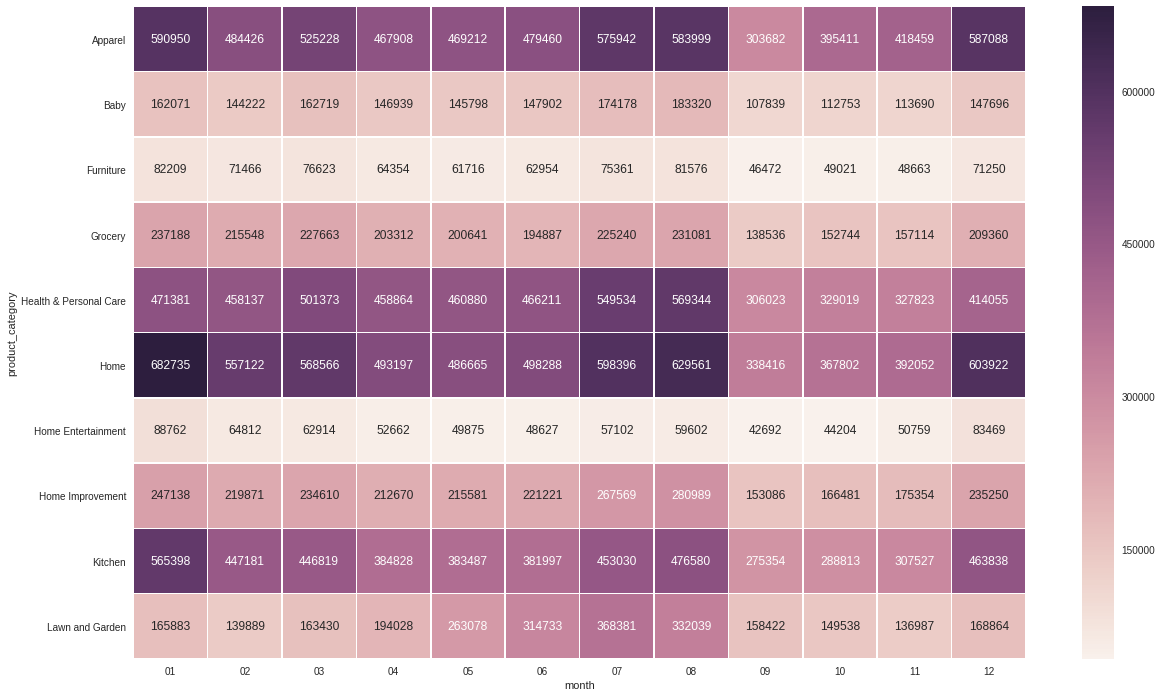

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

MMM = MM.pivot("product_category", "month", "customer_id")
f, ax = plt.subplots(figsize=(20, 12))
sns.heatmap(MMM, annot=True, fmt="d", linewidths=.5, ax=ax)

The heatmap illustrates the number of customer reviewers per month on a per product category basis. Across the product categories, home entertainment and furniture have lesser number of reviewers compared to that of home, apparel, and health & personal care. This suggests two possibilities: i) the number of products in the latter categories are sizable compared to the former; or ii) items in the latter product categories are "fast-moving" compared to those in the former.

In [42]:
prod_categ = dfM.product_category.unique().compute()

[########################################] | 100% Completed | 36.5s


In [43]:
countCust = []
for prod in prod_categ.values:
    newDF =  dfM[dfM.product_category == prod]
    dfMCount = newDF.groupby('month')['customer_id'].apply(lambda x: len(x.unique())).compute()
    dfMCount.index = dfMCount.index.astype(int)
    dfMCountSorted = dfMCount.sort_index()
    countCust.append([dfMCountSorted.index,dfMCountSorted.values]) 

[########################################] | 100% Completed | 44.2s
[########################################] | 100% Completed | 44.3s
[########################################] | 100% Completed | 49.4s
[########################################] | 100% Completed | 38.3s
[########################################] | 100% Completed | 51.9s
[########################################] | 100% Completed | 50.7s
[########################################] | 100% Completed | 42.8s
[########################################] | 100% Completed | 37.7s
[########################################] | 100% Completed | 51.4s
[########################################] | 100% Completed | 43.0s


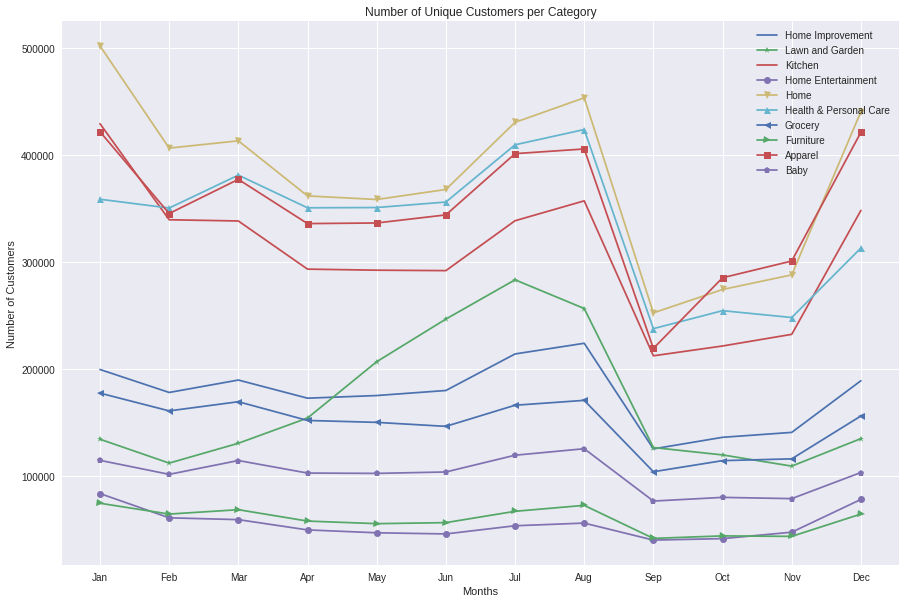

In [44]:
import seaborn as sns;sns.set()
legend_properties = {'size': 10}

markers = ['x','*','+','o','v','^','<','>','s','p']
#i = 0
ticks = dfMCountSorted.index
vals = dfMCountSorted.values
#plt.
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plt.figure(figsize=(15,10))
for i,u in zip(prod_categ.values,range(0,len(prod_categ.values))):
    plt.plot(countCust[u][0], countCust[u][1], marker = markers[u], label = i )
    plt.xticks(ticks)
    plt.legend(prop=legend_properties)
    plt.title("Number of Unique Customers per Category")
    plt.xlabel("Months")
    plt.ylabel("Number of Customers")
    plt.xticks(ticks, months)

Across months (over the years), on the one hand, there is a systemic decline of reviewers engaged between the months August and September. Seemingly, perhaps, customer reviewers are adamant to engage during the so-called "ghost month." On the other hand, interestingly, lawn and garden takes on a good number reviewers during the spring time.

### C. Product designer perspective

The product designer perspective, in general, takes into account how product or product categories can be improved. Some of the points of interest include:
+ What has been the ratings per product category?
+ What are the average ratings of the product categories?
+ What are the average ratings of the product categories over time (yearly)?
+ What are the seasonal (monthly) average ratings of the product categories?
+ Which products have the top rating? bottom rating?
+ How many unique reviewers are there?
+ Which reviewers had the highest number of (helpful) reviews per category?
+ From selected categories, which products have the highest number of reviews?

**C-1 What has been the ratings per product category?**

_"Which product categories have been regarded as better?"_

In [21]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['customer_id','product_category','star_rating'], dtype = {'star_rating':'object'}
                           )
       for fn in filenames]
df = dd.from_delayed(dfs)

[########################################] | 100% Completed | 15.5s


In [22]:
dfP = df[df.product_category.isin(product_categories)].compute()

[########################################] | 100% Completed |  1min 41.6s


In [23]:
dfStarCount = dfP.groupby(['product_category','star_rating'])['customer_id'].apply(lambda x: len(x.unique()))
dfStarCount

product_category        star_rating
Apparel                 1               385322
                        2               322976
                        3               509775
                        4               856359
                        5              2015038
Baby                    1               127407
                        2                88752
                        3               122704
                        4               215129
                        5               653352
Furniture               1                70372
                        2                42722
                        3                70517
                        4               142285
                        5               385558
Grocery                 1               156634
                        2                92646
                        3               132107
                        4               218633
                        5              1011727
Health & Personal Care  

<Figure size 1440x720 with 0 Axes>

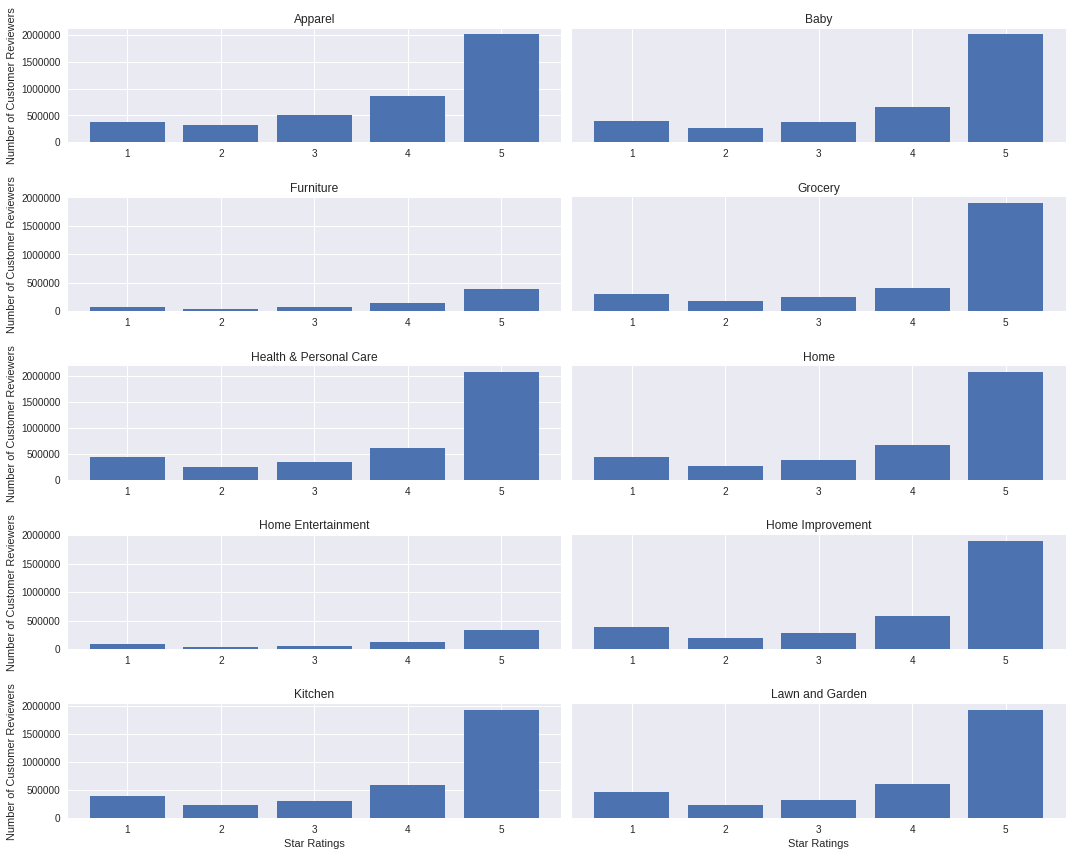

In [24]:
no_categories = int(dfStarCount.shape[0]/5)
yticks = np.arange(0,2230000,500000)
plt.figure(figsize=(20,10)) 
fig, axes = plt.subplots(int(no_categories/2), 2, figsize = (15,12))
ticks = np.arange(1,6,1)
e = 0
for i in range(0, int(no_categories/2)):
    for u in range (0, 2):
        axes[i,u].bar(ticks,dfStarCount.values[(e*5):((e+1)*5)])
        axes[i,u].set_title(dfStarCount.index[e*5][0])
        
        if (i == int(no_categories/2)-1):
            axes[i,u].set_xlabel("Star Ratings")
       
        if (u == 0):
            axes[i,u].set_yticks(yticks)
            axes[i,u].set_ylabel("Number of Customer Reviewers")
            
        else:
            axes[i,u].set_yticks([])
        e += 1
plt.tight_layout()

In the particular case of the select dataset, the reviews were mostly marked as "5". This suggest that collectively the product in the product categories have performed better than expected.

**C-2 What are the average ratings of the product categories?**

_"Over time, what product category has been doing well?"_

In [55]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['product_category','star_rating'], dtype = {'star_rating':'object'}
                           )
       for fn in filenames]
df = dd.from_delayed(dfs)

[########################################] | 100% Completed | 15.4s


In [56]:
dfP = df[df.product_category.isin(product_categories)]

In [57]:
dfP.star_rating = dfP.star_rating.astype(int)

In [58]:
dfPS = dfP.groupby(['product_category'])['star_rating'].apply(lambda x: sum(x)/len(x)).compute()

[########################################] | 100% Completed |  2min 19.7s


Text(0,0.5,'Average Star Ratings')

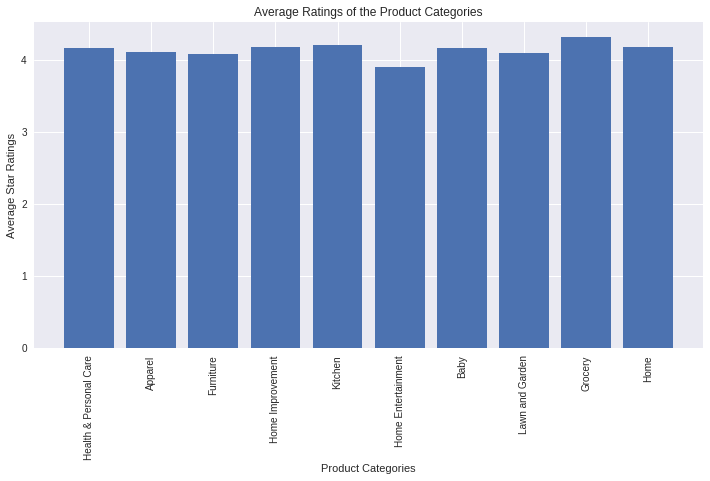

In [59]:
plt.figure(figsize=(12,6))
plt.bar(dfPS.index,dfPS.values)
plt.title('Average Ratings of the Product Categories')
plt.xlabel("Product Categories")
plt.xticks( rotation='90')
plt.ylabel("Average Star Ratings")

In aggregate, over the years, as can be expected from the previous section, the average star rating for the product categories will be toward the positive end of the scale. Further examination might be worthwhile on a per year basis.

**C-3 What are the average ratings of the product categories over time (yearly)?**

_"Over time, what product categories have improved?"_

In [60]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['product_category','star_rating','review_date'], dtype = {'star_rating':'object'}
                           )
       for fn in filenames]
df = dd.from_delayed(dfs)

[########################################] | 100% Completed | 16.0s


In [61]:
dfY = df[df.product_category.isin(product_categories)]

In [62]:
dfY['year'] = dfY['review_date'].str.slice(0,4)

In [63]:
dfY['year'] = dfY['year'].astype(str)

In [64]:
list_years = np.arange(1999,2016,1)
list_years=list_years.astype(str)
dfY= dfY[dfY.year.isin(list_years)]

In [65]:
dfY['year'] =dfY['year'].astype(int)

In [66]:
dfY.star_rating = dfY.star_rating.astype(int)

In [67]:
dfPCYS = dfY.groupby(['product_category','year'])['star_rating'].apply(lambda x: sum(x)/len(x)).compute()

[########################################] | 100% Completed |  4min  9.9s


In [68]:
YY =pd.DataFrame(dfPCYS)
YY.reset_index(inplace=True)

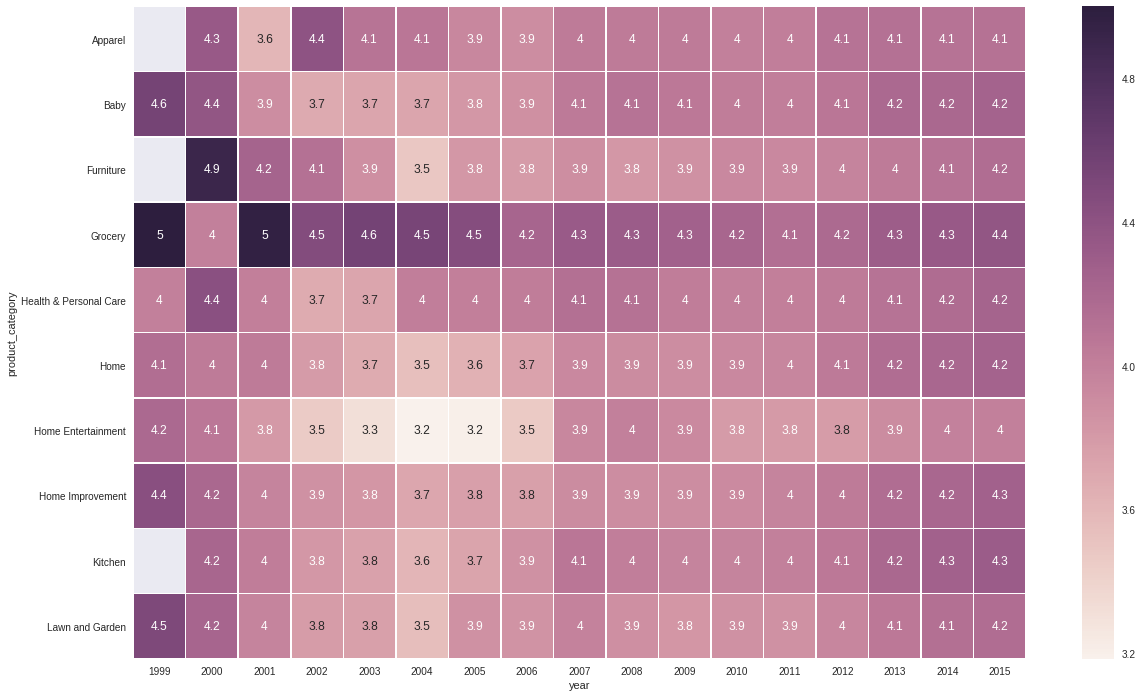

In [69]:
YY = YY.pivot("product_category", "year", "star_rating")
f, ax = plt.subplots(figsize=(20, 12))
sns.heatmap(YY, annot=True, linewidths=.5, ax=ax)

The heatmap above illustrate the average star rating from customer reviewers on the particular year. Because of the volume of reviewers for each product category (see section B-2), a slight change in the average star rating will be significant. For example, in the case of kitchen, the increase can imply that the quality of products within the category has improved.

**C-4 What are the seasonal (monthly) average ratings of the product categories?**

_"Over time, what has been the performance of the product categories?"_

In [70]:
dfM = df[df.product_category.isin(product_categories)]

In [71]:
dfM ['month'] = dfM ['review_date'].str.slice(5,7)

In [72]:
del dfM['review_date']

In [73]:
list_months = ['01','02','03','04','05','06','07','08','09','10','11','12']
dfM = dfM[dfM.month.isin(list_months)]

In [74]:
dfM.head()

[########################################] | 100% Completed | 18.0s


,product_category,star_rating,month
0,Home Improvement,4,08
1,Home Improvement,5,08
2,Home Improvement,5,08
3,Home Improvement,5,08
4,Home Improvement,5,08


In [75]:
dfM.star_rating.unique().compute()

[########################################] | 100% Completed |  2min 13.4s


0    4
1    5
2    1
3    3
4    2
Name: star_rating, dtype: object

In [76]:
dfM.star_rating = dfM.star_rating.astype(int)

In [77]:
dfPCMS = dfM.groupby(['product_category','month'])['star_rating'].apply(lambda x: sum(x)/len(x)).compute()

[########################################] | 100% Completed |  3min 39.9s


In [78]:
dfPCMS.head()

product_category        month
Apparel                 07       4.107867
Baby                    12       4.166003
Furniture               01       4.088068
Health & Personal Care  03       4.159394
                        05       4.170407
Name: star_rating, dtype: float64

In [79]:
MM =pd.DataFrame(dfPCMS)
MM.reset_index(inplace=True)

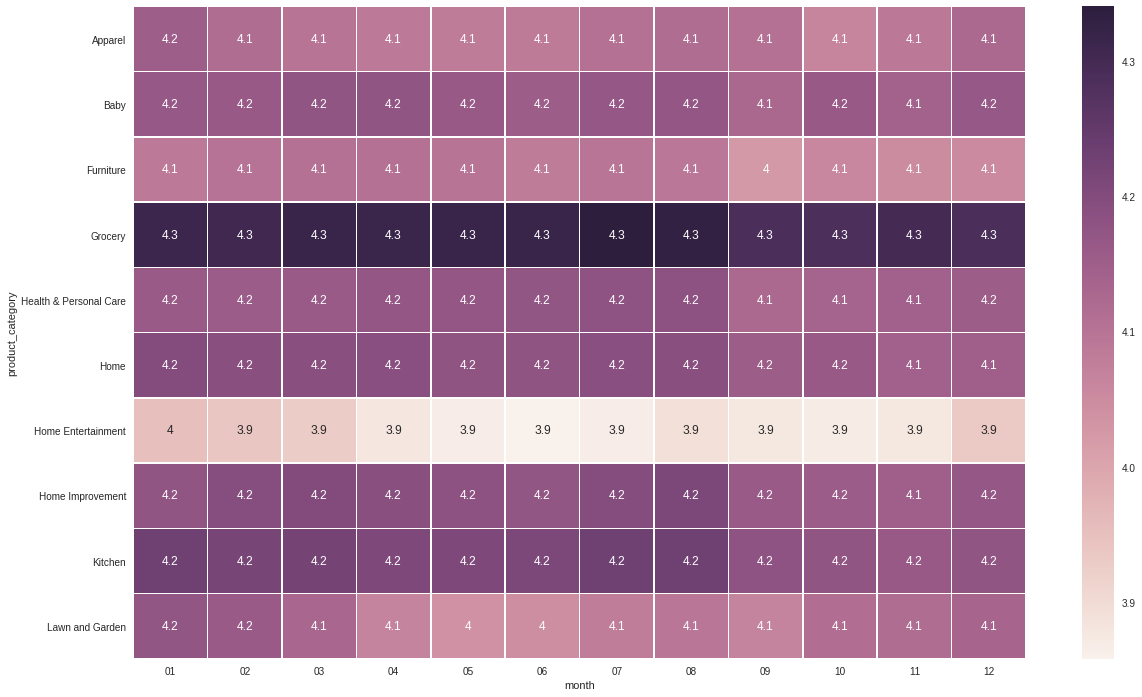

In [80]:
MMM = MM.pivot("product_category", "month", "star_rating")
f, ax = plt.subplots(figsize=(20, 12))
sns.heatmap(MMM, annot=True, linewidths=.5, ax=ax)

Similar to how it was done on a yearly basis, the monthly view can imply the (seasonal) approval of customer reviewers.

**C-5 Which products have the top rating? bottom rating?**

It is also plausible to take a look at the "micro-level" or on a per item basis.

In [81]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['product_category','star_rating','product_title'], dtype = {'star_rating':'object'}
                           )
       for fn in filenames]
df = dd.from_delayed(dfs)

[########################################] | 100% Completed | 17.7s


In [82]:
dfM = df[df.product_category.isin(product_categories)]

In [83]:
del dfM['product_category']

In [84]:
dfM.star_rating = dfM.star_rating.astype(int)

In [85]:
dfPCPT = dfM.groupby(['product_title'])['star_rating'].apply(lambda x: sum(x)/len(x)).compute()

[########################################] | 100% Completed | 13min 53.0s


In [86]:
dfPT =pd.DataFrame(dfPCPT)
dfTopRating = dfPT[dfPT.star_rating== 5.0]

In [87]:
dfTopRating.head(10)

,star_rating
product_title,
American Flag Garden - Americana - Hydrangeas - Mailbox Makeover Vinyl Magnetic Cover,5.0
BRRING ON THE SNOW - Winter / Christmas Themed - Standard Size 28 Inch X 40 Inch - Decorative DOUBLE SIDED Flag,5.0
Being a Crabby Bitch Is Part of My Charm Mug,5.0
CHER ST STREET SIGN NAME,5.0
CHEVRON OWL - Fall Themed - Double Sided - Garden Size 12 Inch X 18 Inch - Decorative Flag,5.0
CHRISTMAS WISHES - Christmas Themed - Standard Size 28 Inch X 40 Inch - Decorative DOUBLE SIDED Flag,5.0
CRABBY DOGS - Double Sided GARDEN Size Decorative Flag 12 X 18 Inches,5.0
Farm Truck - Decorative Mailbox Makeover - Rural Size Mailbox Magnetic Cover,5.0
Garden Kitties - Decorative Mailbox Makeover - Rural Size Mailbox Magnetic Cover,5.0


In [88]:
len(dfTopRating)

1610152

In [89]:
dfBottomRating = dfPT[dfPT.star_rating== 1.0]

In [90]:
dfBottomRating.head(10)

,star_rating
product_title,
"Blue Paradise, Third Impression Yellow Sandy Beach Modern Art Work Hand Painted Oil Painting on Canvas Stretched & Framed",1.0
MCPHERSON ST STREET SIGN,1.0
PRINCESS ZELDA PARKING ONLY PARKING SIGN,1.0
"#1 PURE Garcinia Cambogia Extract -Garcinia Cambogia-60 Veggie Capsules (Featuring Clinically-Proven, Multi-Patented 50% HCA Extract for Weight-Loss) 1,500 mg per Serving",1.0
#1 Red Molded Candle,1.0
#1 Trusted Ultra Eliminex Detox 32 OZ Detoxification Drink & FREE Q-Pretox Master Concentrated Capsules (100 ct.) for the Ultimate Detoxify 1-2 Punch! Ultra Maximum Strength Elite Detoxify Beverage - Fast Easy Full Body Toxin Elimination for People With High Toxin Levels or Larger Body Mass. Get Clean Today.,1.0
"#10 Deluxe Heavy Duty Manual Tinned Meat Grinder (3 stuffing funnesl, stuffing stars, flange, 2 SS grinder",1.0
#10 pounds of roasted whole coffee beans from Blue Bell Mountain Coffee,1.0
"#1028 - BEST SELLER - Formal Evening Gown. Mother of the Bride/Groom Short Sleeve V Neck with beads all over - (Available in Off White, Sage, Red, Black, Gold in XS to 4XL)",1.0


In [92]:
len(dfBottomRating)

233552

**C-6 How many unique reviewers are there?**

_"How many can we tap to get feedback from?"_ If we want to improve a product, it becomes an option to recognize the critics. The reviews from vocal customers provide opportunities to pivot the product in the category.

In [93]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['customer_id','product_category']
                           )
       for fn in filenames]
df = dd.from_delayed(dfs)

[########################################] | 100% Completed | 16.4s


In [94]:
dfM = df[df.product_category.isin(product_categories)]

In [95]:
del dfM['product_category']

In [96]:
dfM.customer_id.nunique().compute()

[########################################] | 100% Completed |  1min 53.5s


11574563

**C-7 Which reviewers had the highest number of (helpful) reviews per category?**

_"Who are the influencers we can pull in for help with product improvement?"_

In [12]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['customer_id','product_category','helpful_votes']
                           )
       for fn in filenames]
df = dd.from_delayed(dfs)

[########################################] | 100% Completed | 15.1s


In [13]:
dfR = df[df.product_category.isin(product_categories)]

In [14]:
dfR.helpful_votes = dfR.helpful_votes.astype(int)

In [15]:
product_categories.remove('Health Personal Care')

[########################################] | 100% Completed |  6min  6.2s
[########################################] | 100% Completed |  5min 40.6s
[########################################] | 100% Completed |  8min 52.9s
[########################################] | 100% Completed |  3min 15.9s
[########################################] | 100% Completed | 10min  4.7s
[########################################] | 100% Completed |  4min 44.3s
[########################################] | 100% Completed |  3min 13.4s
[########################################] | 100% Completed |  8min 45.2s
[########################################] | 100% Completed |  3min 52.0s
[########################################] | 100% Completed |  8min 43.3s


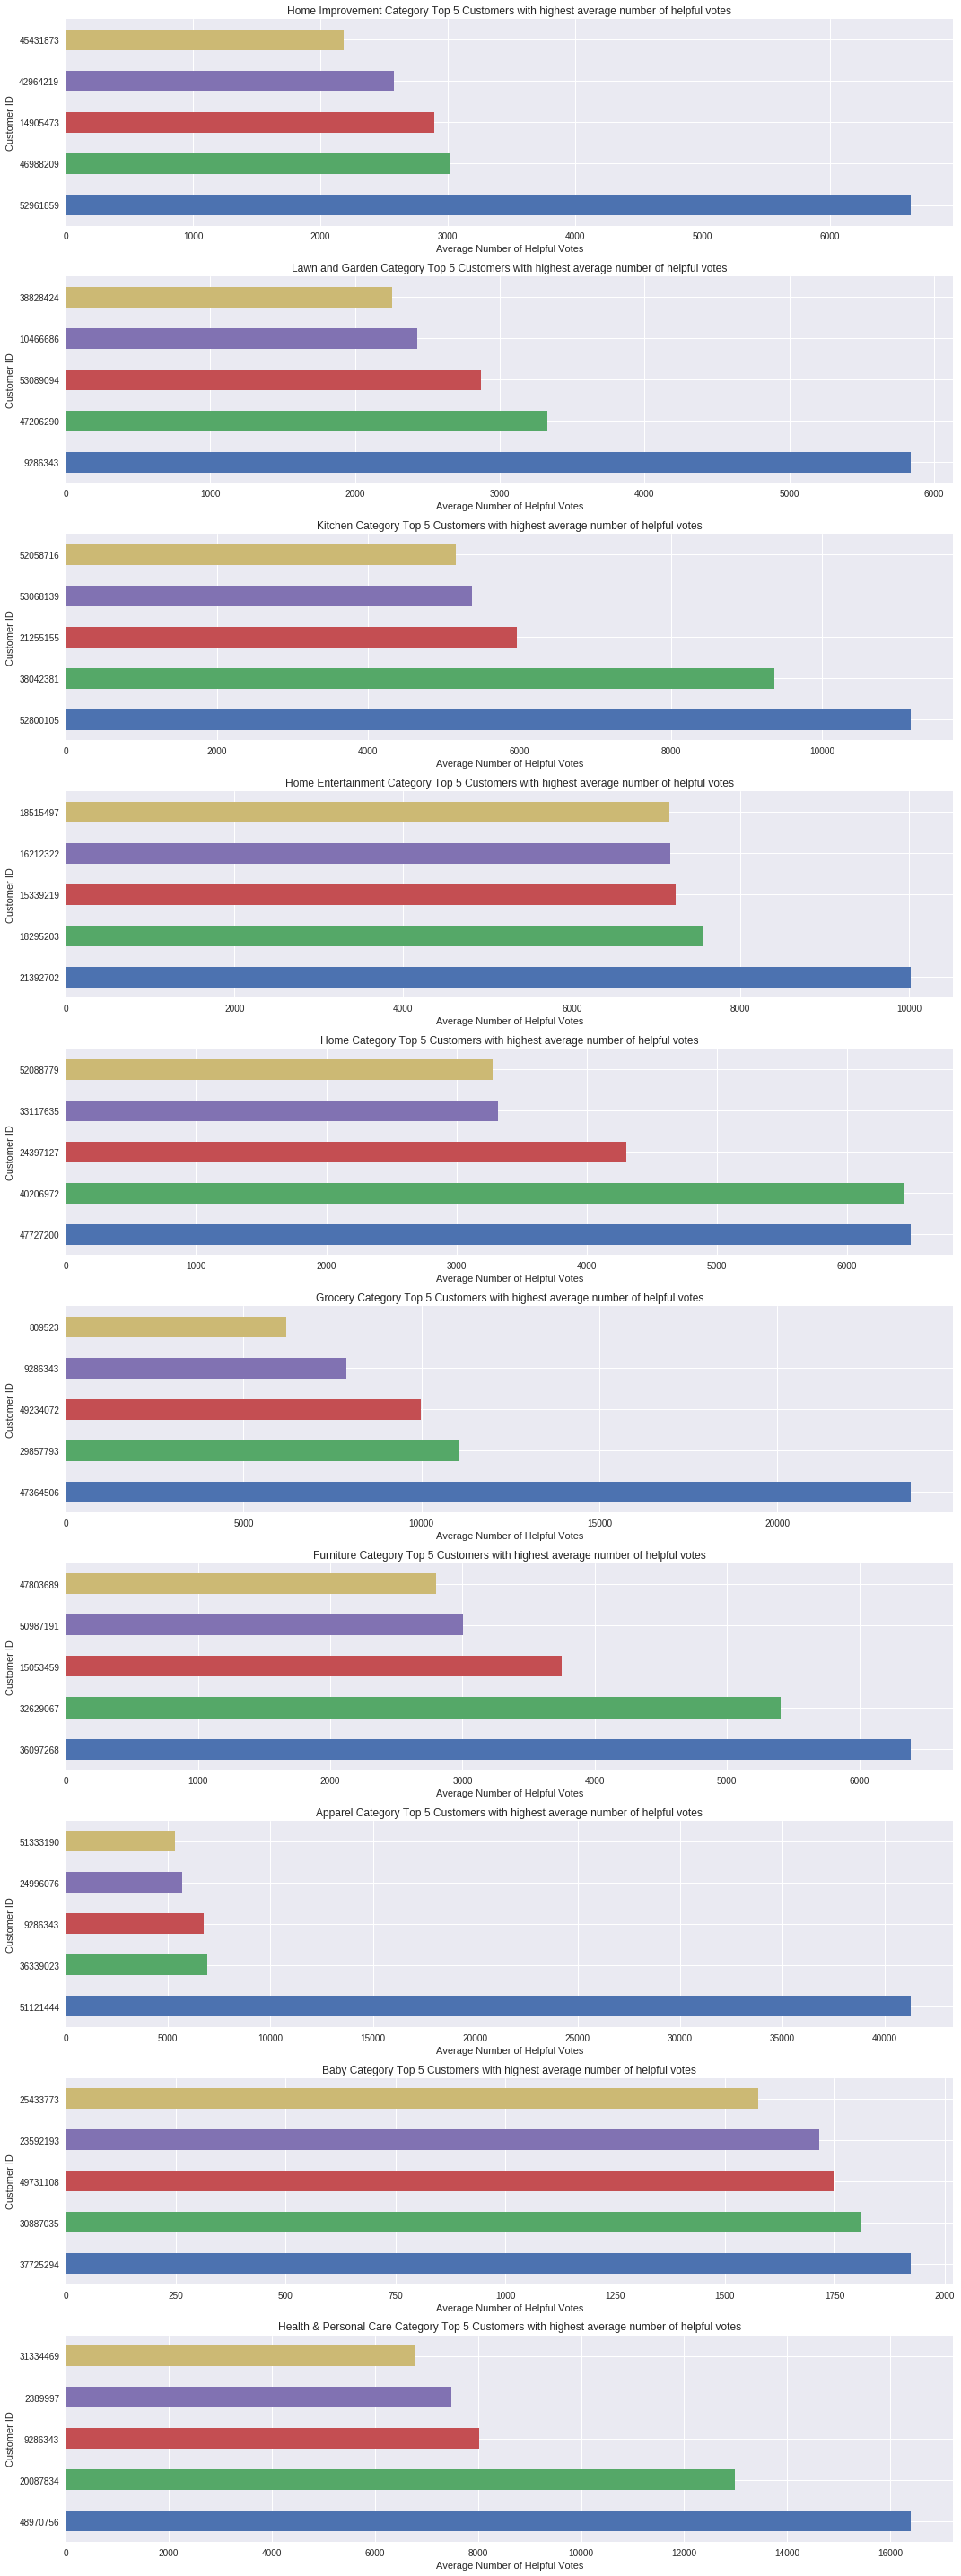

In [16]:
fig, axes = plt.subplots(10, 1, figsize = (15,40))
for prod,i in zip(product_categories, range(0,10)):    
    dfTemp = dfR[dfR.product_category == prod]
    dfH = dfTemp.groupby('customer_id')['helpful_votes'].apply(lambda x: sum(x)/len(x)).compute()
    dfHH =pd.DataFrame(dfH)
    dfHH = dfHH.helpful_votes.sort_values(ascending = False)[:5]
    dfHH.plot(kind='barh', ax=axes[i])
    axes[i].set_title(prod + ' Category Top 5 Customers with highest average number of helpful votes')
    axes[i].set_ylabel("Customer ID")
    axes[i].set_xlabel("Average Number of Helpful Votes")
fig.tight_layout()
fig.show()

**C-8 From selected categories, which products have the highest number of reviews?**

In a similar manner, identifying the products with the most reviews aid in product design. Such products can serve as benchmark for succeeding iterations of product or product lines.

In [10]:
dfs = [delayed(pd.read_csv)(path + fn, delimiter='\t', error_bad_lines = False,  compression  ='gzip',
                            header = 0,
                           usecols = ['customer_id','product_category','product_title','review_date']
                           )
       for fn in selected_filenames]
df = dd.from_delayed(dfs)

[########################################] | 100% Completed | 35.8s


In [11]:
selected_product_categories = ['Home','Health & Personal Care', 'Apparel']

In [12]:
dfNR = df[df.product_category.isin(selected_product_categories)]

In [13]:
dfNR['product_title'] = dfNR['product_title'].str[:20]

[########################################] | 100% Completed |  3min 14.4s
[########################################] | 100% Completed |  2min 24.9s
[########################################] | 100% Completed |  2min 56.5s


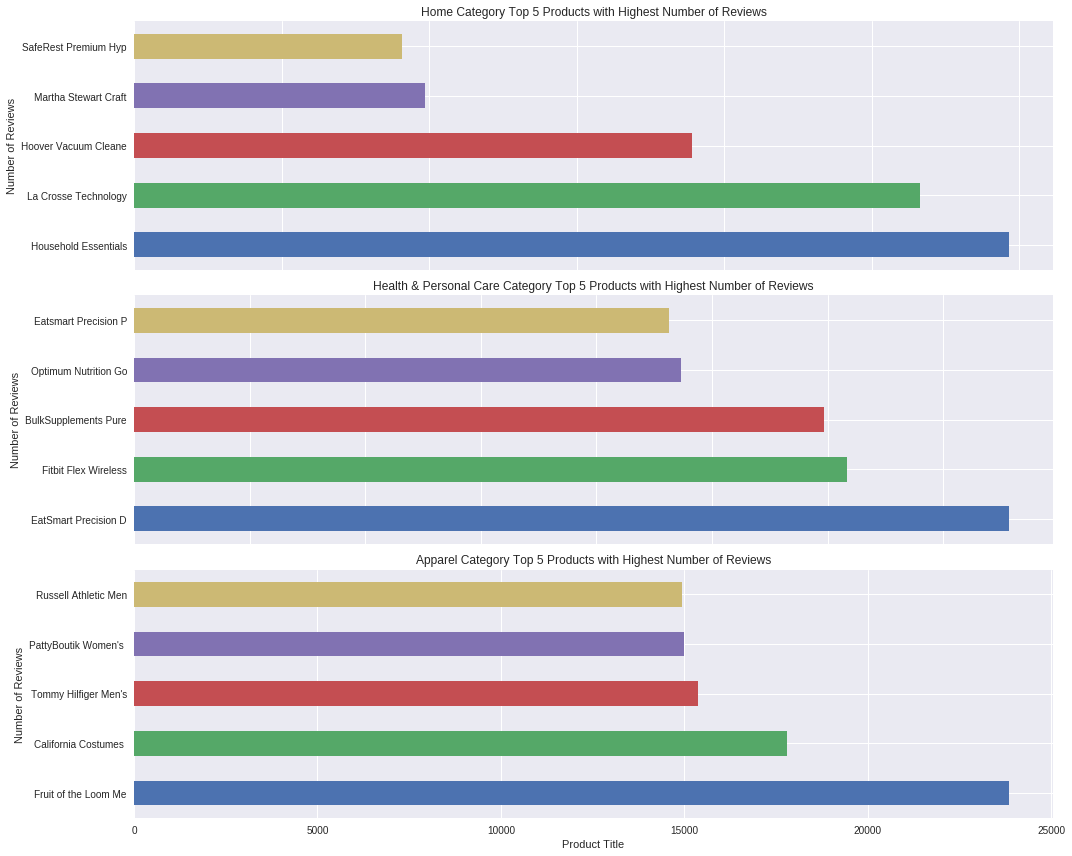

In [20]:
fig, axes = plt.subplots(3, 1, figsize = (15,12))
for prod,i in zip(selected_product_categories, range(0,3)):    
    dfTemp = dfNR[dfNR.product_category == prod]
    dfH = dfTemp.groupby('product_title')['customer_id'].apply(lambda x: len(x.unique())).compute()
    dfHH =pd.DataFrame(dfH)
    dfHH = dfHH.customer_id.sort_values(ascending = False)[:5]
#     dfHH.plot(kind='barh', ax=axes[i], sharex=True)
    dfHH.plot(kind='barh', ax=axes[i], sharex=True)
    axes[i].set_title(prod + ' Category Top 5 Products with Highest Number of Reviews')
    axes[i].set_xlabel("Product Title")
    axes[i].set_ylabel("Number of Reviews")
fig.tight_layout()
fig.show()

### REFERENCES

[1] Xu, K., Liao, S. S., Li, J., & Song, Y. (2011). Mining comparative opinions from customer reviews for Competitive Intelligence. Decision support systems, 50(4), 743-754.

[2] Zhang, K., Narayanan, R., & Choudhary, A. N. (2010). Voice of the Customers: Mining Online Customer Reviews for Product Feature-based Ranking. WOSN, 10, 11-11.

[3] Ferreira, L., Jakob, N., & Gurevych, I. (2008, August). A comparative study of feature extraction algorithms in customer reviews. In Semantic Computing, 2008 IEEE International Conference on (pp. 144-151). IEEE.

[4] Burns, N., Bi, Y., Wang, H., & Anderson, T. (2011, September). Sentiment analysis of customer reviews: Balanced versus unbalanced datasets. In International Conference on Knowledge-Based and Intelligent Information and Engineering Systems (pp. 161-170). Springer, Berlin, Heidelberg.

[5] Alis, C. (2018). Session notes in BDCC. Asian Institute of Management, Makati.

### ACKNOWLEDGEMENT

We are thankful to the rest of the MSDS2019 cohort for the exchange of ideas at the library.